In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import parallel_coordinates
import seaborn as sns
import numpy as np

# df_PT

In [9]:
Student_dropout = pd.read_csv('data/data.csv', sep=';')

In [10]:
Student_dropout.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [11]:
Student_dropout['Target'] = Student_dropout['Target'].replace('Graduate', 0).replace('Enrolled', 0).replace('Dropout', 1)

C:\Users\gusta\AppData\Local\Temp\ipykernel_18408\398414641.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Student_dropout['Target'] = Student_dropout['Target'].replace('Graduate', 0).replace('Enrolled', 0).replace('Dropout', 1)


### Variáveis
- Todas as variáveis estão oficialmente em int ou float, garantindo que consiguimos comparar eles de maneira numérica

In [12]:
binary = [
    'Gender',
    'Displaced',
    'Scolarship Holder',
    'Educational special needs',
    'Debtor',
    'Tuition fees up to date'
]

Continuous= [
    'Admission grade',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

In [13]:
drop = [col for col in Student_dropout.columns if col.startswith('Curricular units 2nd sem') and col != 'Curricular units 2nd sem (without evaluations)'] + ['Father\'s occupation', 'International']
Student_dropout.drop(columns=drop, inplace=True)

# Coding
Now that we cleaned our database and treated any thing that could cause trouble, it's time we start coding

In [14]:
from imblearn.over_sampling import RandomOverSampler
def oversampling(X, y):
    sampler = RandomOverSampler(random_state=42)
    X_resampled, y_resampled = sampler.fit_resample(X, y)
    return X_resampled, y_resampled

In [15]:
import sklearn.model_selection

y = Student_dropout['Target']
X = Student_dropout.drop(columns=['Target'])

X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)
X_oversampled, y_oversampled = oversampling(X_train, y_train)

In [16]:
from numbers import Number

class Question():
    def __init__(self, column, value):
        self.column = column
        self.value = value
    
    def match(self, example):
        val = example[self.column]
        if isinstance(val, (Number, np.number)):
            return val >= self.value
        else:
            return val == self.value

    def __repr__(self):
        condition = "=="
        if isinstance(self.value, (int, float, np.number)):
            condition = ">="
        return f"Is {self.column} {condition} {str(self.value)}?"


In [17]:
def partition(rows, y, question):
    """
    Divide os dados de cada uma das linhas em duas listas,
    A primeira tem todos aqueles que respondem a pergunta;
    Já a segunda tem todos aqueles que não respondem a pergunta.
    """
    col_vals = rows[:, question.column]
    if isinstance(question.value, (Number, np.number)):
        mask = col_vals >= question.value
    else:
        mask = col_vals == question.value

    return (rows[mask], y[mask]), (rows[~mask], y[~mask])

def class_counts(y):  
    #Lista quantas vezes aparece na coluna de evasão os evadidos e não evadidos 
    counts = {}
    unique, cts = np.unique(y, return_counts=True)
    for label, c in zip(unique, cts):
        counts[int(label)] = int(c)
    return counts


def gini(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probs = counts / float(len(y))
    return 1.0 - np.sum(probs ** 2)

def info_gain(left_y, right_y, current_uncertainty):
    p = float(len(left_y)) / (len(left_y) + len(right_y))
    return current_uncertainty - p * gini(left_y) - (1 - p) * gini(right_y)
    
def find_best_split(rows, y, n_features, max_features=None):
    """
    Define a melhor pergunta para dividir os dados com base 
    no ganho de conhecimento (information gain) e no índice de Gini.
    """
    best_gain = 0
    best_question = None
    curr_gini = gini(y)
    total_cols = rows.shape[1] if n_features is None else min(n_features, rows.shape[1])

    if max_features is not None and max_features < total_cols:
        col_indices = np.random.choice(total_cols, size=max_features, replace=False)
    else:
        col_indices = range(total_cols)

    for col in col_indices:
        col_data = rows[:, col]
        unique_vals = np.unique(col_data)
        if len(unique_vals) > 25:
            values = np.unique(np.percentile(col_data, np.linspace(5, 95, 19)))
        else:
            values = unique_vals

        for val in values:
            question = Question(col, val)
            (_, true_labels), (_, false_labels) = partition(rows, y, question)

            if len(true_labels) > 0 and len(false_labels) > 0:
                gain = info_gain(true_labels, false_labels, curr_gini)
                if gain >= best_gain:
                    best_gain, best_question = gain, question

    return best_gain, best_question

In [18]:
from collections import Counter
class DecisionNode():
    #Tem filhos, é uma etapa de pergunta, e não uma folha da árvore de decisão.
    def __init__(self, question, true_branch, false_branch):
        self.question = question
        self.true_branch = true_branch
        self.false_branch = false_branch

    def predict(self, row):
        if isinstance(self, Leaf):
            return self.predictions
        if self.question.match(row):
            return self.true_branch.predict(row)
        else:
            return self.false_branch.predict(row)
        
    def predict_all(self, rows):
        return [self.predict(row) for row in rows]

class Leaf():
    #Não tem filhos, é a resposta final da árvore de decisão.
    def __init__(self, predictions):
        self.predictions = Counter(predictions).most_common(1)[0][0]

    def predict(self, row):
        return self.predictions

    def predict_all(self, rows):
        return [self.predictions for _ in rows]

In [19]:
class DecisionTree():
    def __init__(self, x, y, minSplit = 2, maxDepth = 5, n_features=29, max_features=None):
        self.x = x
        self.y = y
        self.minSplit = minSplit
        self.maxDepth = maxDepth
        self.n_features = n_features
        self.max_features = max_features
        
    def buildTree(self, curr_depth = 0):
        #Constrói a árvore de decisão recursivamente.
        n_samples = len(self.x)
        if n_samples < self.minSplit or curr_depth >= self.maxDepth or len(np.unique(self.y)) == 1:
            return Leaf(self.y)

        gain, question = find_best_split(self.x, self.y, self.n_features, self.max_features)

        if gain == 0 or question is None:
            return Leaf(self.y)
        (true_rows, true_labels), (false_rows, false_labels) = partition(self.x, self.y, question)


        if len(true_rows) == 0 or len(false_rows) == 0:
            return Leaf(self.y)
        
        curr_depth += 1
        true_branch = DecisionTree(true_rows, true_labels, self.minSplit, self.maxDepth, self.n_features, self.max_features).buildTree(curr_depth)
        false_branch = DecisionTree(false_rows, false_labels, self.minSplit, self.maxDepth, self.n_features, self.max_features).buildTree(curr_depth)

        return DecisionNode(question, true_branch, false_branch)

## Random Forest


Random forets são um coletivo de árvores de decisão treinadas com um conjunto de dados selecionados aleatoriamente e com reposição em um data set. Além disso, os features analisados são também escolhidos de maneira aleatória

In [20]:
import random


class randomForest():
    def __init__(self, n_trees=25, minSplit=2, maxDepth=8, sample_size=None, max_features=None, seed=42):
        self.n_trees = n_trees
        self.minSplit = minSplit
        self.maxDepth = maxDepth
        self.sample_size = sample_size
        self.max_features = max_features
        self.seed = seed
        self.trees = []

    def buildForest(self, x, y):
        if self.seed is not None:
            np.random.seed(self.seed)
        self.trees = []
        n_samples = len(x)
        k = self.sample_size if self.sample_size is not None else n_samples
        m_feat = self.max_features if self.max_features is not None else int(np.sqrt(x.shape[1]))

        for i in range(self.n_trees):
            indices = np.random.choice(n_samples, size=k, replace=True)
            new_x = x[indices]
            new_y = y[indices]
            tree = DecisionTree(new_x, new_y, self.minSplit, self.maxDepth, n_features=x.shape[1], max_features=m_feat)
            self.trees.append(tree.buildTree())
        
        return self.trees
    
    def predict(self, row):
        predictions = [tree.predict(row) for tree in self.trees]
        
        count = Counter(predictions)
        classe_mais_votada, _ = count.most_common(1)[0]
        
        return classe_mais_votada
    
    def predict_all(self, rows):
        return [self.predict(row) for row in rows]

In [25]:
myForest = randomForest()
myForest.buildForest(X_train.values, y_train.values)
myForestPredictions = myForest.predict_all(X_test.values)

myOverForest = randomForest()
myOverForest.buildForest(X_oversampled.values, y_oversampled.values)
myOverForestPredictions = myOverForest.predict_all(X_test.values)

In [26]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forestPredictions = forest.predict(X_test)

overForest = RandomForestClassifier(n_estimators=100, random_state=42)
overForest.fit(X_oversampled, y_oversampled)
overForestPredictions = overForest.predict(X_test)

# Comparação dos resultados

Acurácia da Árvore de Decisão Normal:
0.8384180790960452
Matriz de Confusão da Árvore de Decisão Normal:


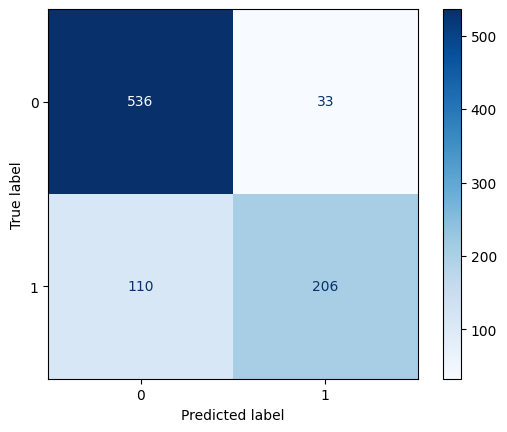

------------------------------------




Acurácia da Árvore de Decisão com Dados Oversampled:
0.8451977401129943
Matriz de Confusão da Árvore de Decisão com Dados Oversampled:


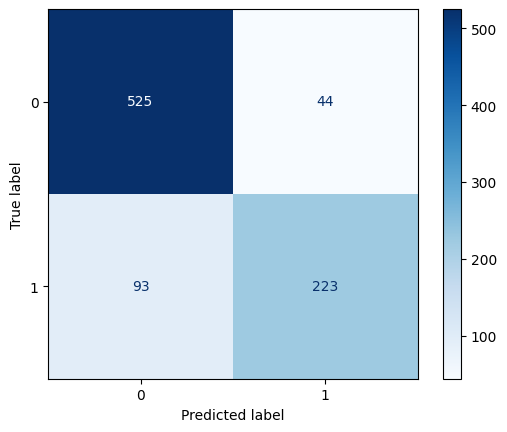

------------------------------------




Acurácia da Árvore de Decisão Implementada:
0.8327683615819209
Matriz de Confusão da Árvore de Decisão Implementada:


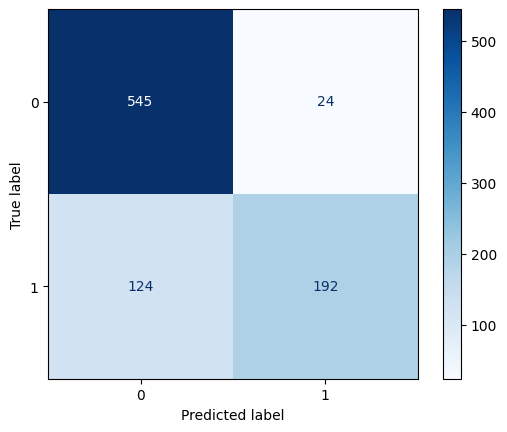

------------------------------------




Acurácia da Árvore de Decisão Implementada com Dados Oversampled:
0.823728813559322
Matriz de Confusão da Árvore de Decisão Implementada com Dados Oversampled:


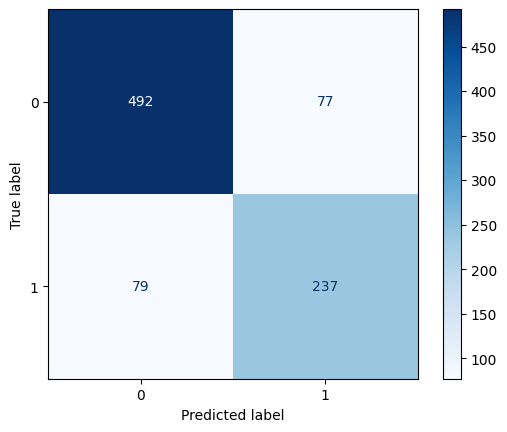

------------------------------------




In [27]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ----------------------------------- #
# =========== Acurácia ============== #
# ----------------------------------- #


print("Acurácia da Árvore de Decisão Normal:")
print(accuracy_score(y_test, forestPredictions))
print("Matriz de Confusão da Árvore de Decisão Normal:")
cm = confusion_matrix(y_test, forestPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia da Árvore de Decisão com Dados Oversampled:")
print(accuracy_score(y_test, overForestPredictions))
print("Matriz de Confusão da Árvore de Decisão com Dados Oversampled:")
cm = confusion_matrix(y_test, overForestPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia da Árvore de Decisão Implementada:")
print(accuracy_score(y_test, myForestPredictions))
print("Matriz de Confusão da Árvore de Decisão Implementada:")
cm = confusion_matrix(y_test, myForestPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")

print("Acurácia da Árvore de Decisão Implementada com Dados Oversampled:")
print(accuracy_score(y_test, myOverForestPredictions))
print("Matriz de Confusão da Árvore de Decisão Implementada com Dados Oversampled:")
cm = confusion_matrix(y_test, myOverForestPredictions)
disp=ConfusionMatrixDisplay(cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()
print("------------------------------------")
print("\n")